         Date      Time  CO(GT)  PT08.S1(CO)  NMHC(GT)  C6H6(GT)  \
0  10/03/2004  18.00.00     2.6       1360.0     150.0      11.9   
1  10/03/2004  19.00.00     2.0       1292.0     112.0       9.4   
2  10/03/2004  20.00.00     2.2       1402.0      88.0       9.0   
3  10/03/2004  21.00.00     2.2       1376.0      80.0       9.2   
4  10/03/2004  22.00.00     1.6       1272.0      51.0       6.5   

   PT08.S2(NMHC)  NOx(GT)  PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  PT08.S5(O3)  \
0         1046.0    166.0        1056.0    113.0        1692.0       1268.0   
1          955.0    103.0        1174.0     92.0        1559.0        972.0   
2          939.0    131.0        1140.0    114.0        1555.0       1074.0   
3          948.0    172.0        1092.0    122.0        1584.0       1203.0   
4          836.0    131.0        1205.0    116.0        1490.0       1110.0   

      T    RH      AH            DateTime  
0  13.6  48.9  0.7578 2004-03-10 18:00:00  
1  13.3  47.7  0.7255 2004-0

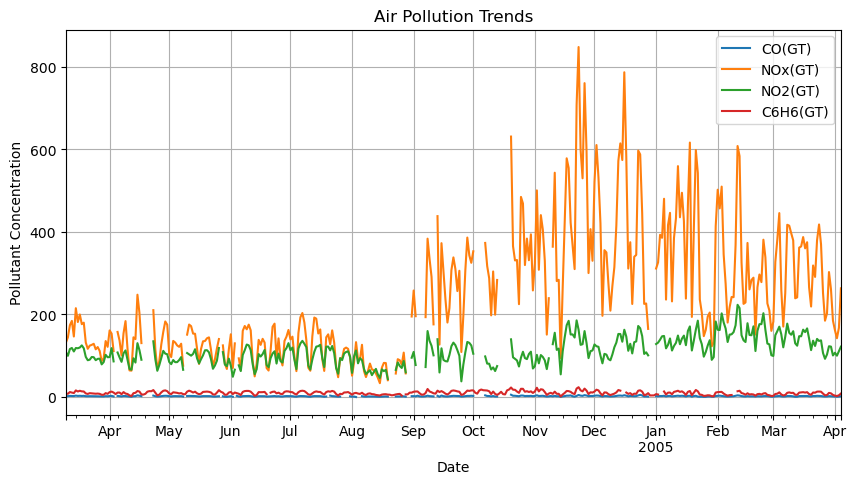

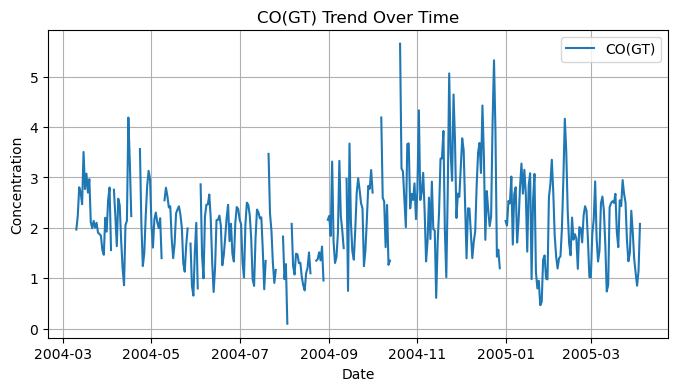

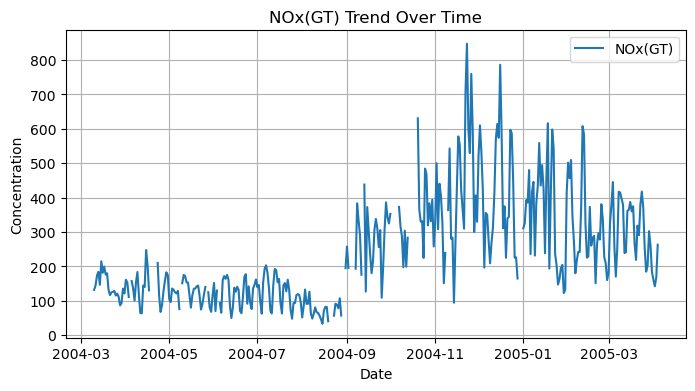

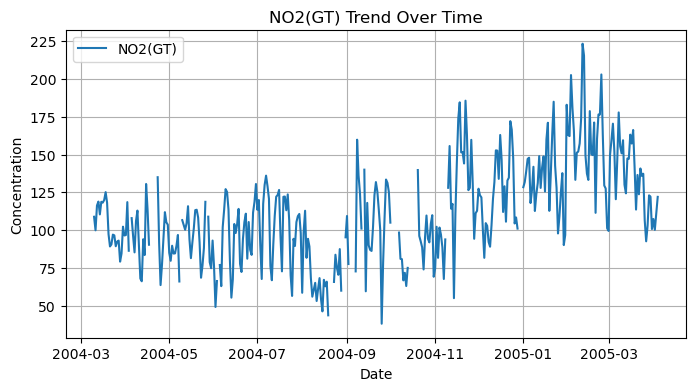

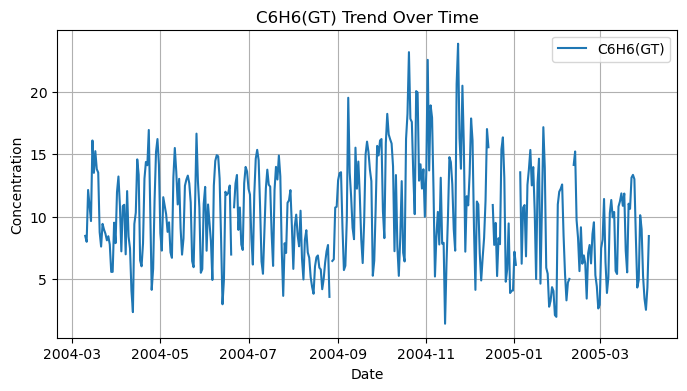

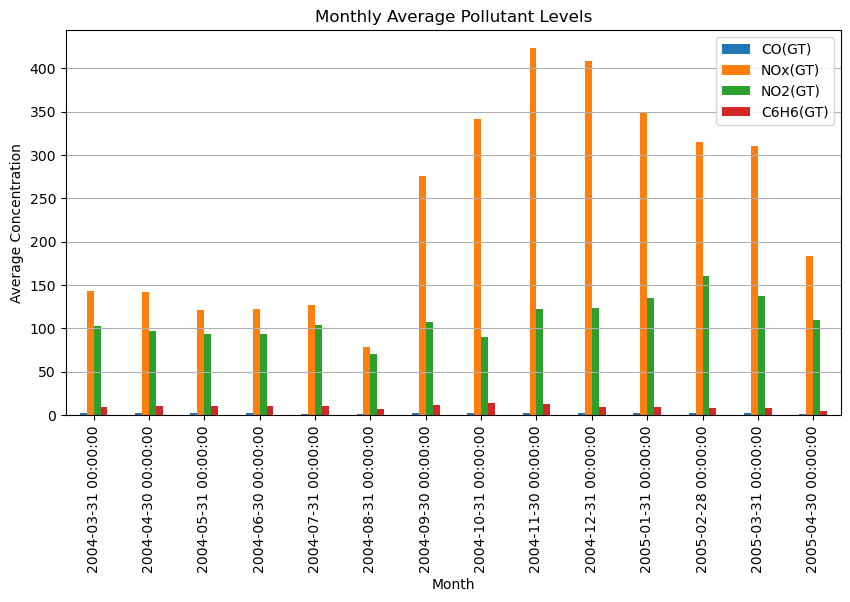

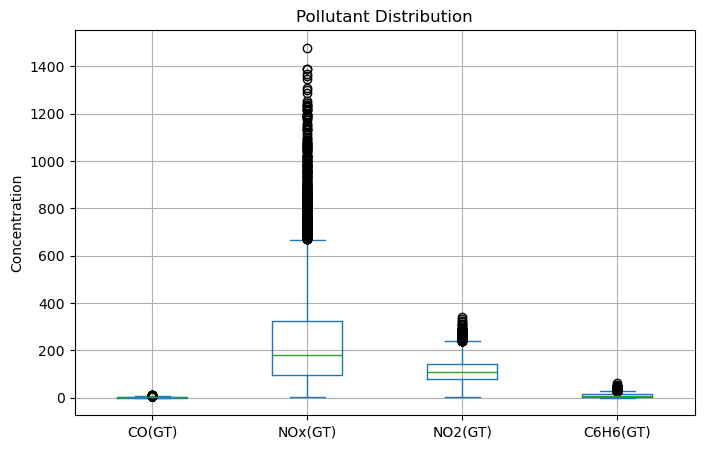

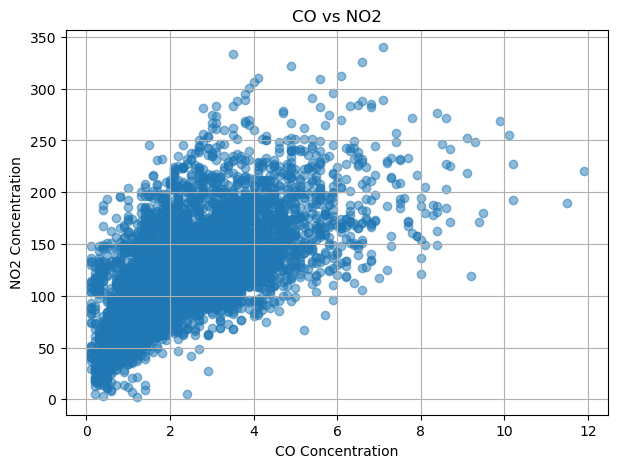

In [8]:
# Task 1: Import libraries and load dataset
import pandas as pd
import matplotlib.pyplot as plt

# Read CSV (semicolon separator, comma decimal)
data = pd.read_csv("City_Air_Quality.csv", sep=";",
                   decimal=",", na_values=[-200])

# Remove empty columns
data = data.loc[:, ~data.columns.str.contains("^Unnamed")]

# Combine Date and Time
data["DateTime"] = pd.to_datetime(
    data["Date"] + " " + data["Time"],
    format="%d/%m/%Y %H.%M.%S"
)

# Task 2: Explore dataset
print(data.head())
print(data.info())
print(data.describe())
print(data.isnull().sum())

# Task 3: Select relevant variables
pollutants = ["CO(GT)", "NOx(GT)", "NO2(GT)", "C6H6(GT)"]

# Calculate daily average pollutant levels
daily = data.set_index("DateTime")[pollutants].resample("D").mean()

# Task 4: Line plot for overall pollution trends
daily.plot(figsize=(10, 5), title="Air Pollution Trends")
plt.xlabel("Date")
plt.ylabel("Pollutant Concentration")
plt.grid()
plt.show()

# Task 5: Individual pollutant trends
for col in pollutants:
    plt.figure(figsize=(8, 4))
    plt.plot(daily.index, daily[col], label=col)
    plt.title(col + " Trend Over Time")
    plt.xlabel("Date")
    plt.ylabel("Concentration")
    plt.legend()
    plt.grid()
    plt.show()

# Task 6: Bar plot for monthly average pollutant levels
monthly = daily.resample("ME").mean()
monthly.plot(kind="bar", figsize=(10, 5))
plt.title("Monthly Average Pollutant Levels")
plt.xlabel("Month")
plt.ylabel("Average Concentration")
plt.grid(axis="y")
plt.show()

# Task 7: Box plot for pollutant distribution
data[pollutants].plot(kind="box", figsize=(8, 5))
plt.title("Pollutant Distribution")
plt.ylabel("Concentration")
plt.grid()
plt.show()

# Task 8: Scatter plot showing relationship between pollutants
plt.figure(figsize=(7, 5))
plt.scatter(data["CO(GT)"], data["NO2(GT)"], alpha=0.5)
plt.title("CO vs NO2")
plt.xlabel("CO Concentration")
plt.ylabel("NO2 Concentration")
plt.grid()
plt.show()

# Task 9: Visualization customization
# Titles, labels, legends, colors, and grid lines
# have been added to the above visualizations.